# 03. DART 보고서 전처리

`data/processed/dart_reports/*.json`에서 `sections`의 `II`, `IV`, `VI` 세 구간을 하나의 텍스트로 묶고, 기본 정제 후 Kiwi 형태소 분석기에 입력할 수 있는 데이터프레임을 만듭니다.

- 현재 로컬 기준: JSON 381개, 체크포인트 CSV 381행
- `sections`가 비어 있는 FAIL 행은 보존하되 `text_clean=''`, `tokens=[]`, `token_count=0`으로 처리합니다.

## 1. 라이브러리 import 및 경로 설정

In [1]:
import json
import re
from pathlib import Path

import pandas as pd
from kiwipiepy import Kiwi

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

REPORT_DIR = PROJECT_ROOT / "data" / "processed" / "dart_reports"
CHECKPOINT_PATH = PROJECT_ROOT / "data" / "processed" / "dart_collection_checkpoint.csv"
OUTPUT_PATH = PROJECT_ROOT / "data" / "processed" / "dart_morph_ready.csv"

SECTION_KEYS = ["II", "IV", "VI"]

REPORT_DIR, CHECKPOINT_PATH, OUTPUT_PATH

(PosixPath('/Users/home1/Documents/esg-dart-project/data/processed/dart_reports'),
 PosixPath('/Users/home1/Documents/esg-dart-project/data/processed/dart_collection_checkpoint.csv'),
 PosixPath('/Users/home1/Documents/esg-dart-project/data/processed/dart_morph_ready.csv'))

## 2. JSON 로드 후 메타데이터와 원본 section 길이 확인

In [2]:
def load_report_row(path: Path) -> dict:
    with path.open("r", encoding="utf-8") as f:
        report = json.load(f)

    sections = report.get("sections") or {}
    row = {
        "file_name": path.name,
        "company_name": report.get("company_name"),
        "stock_code": str(report.get("stock_code", "")).zfill(6),
        "corp_code": report.get("corp_code"),
        "esg_year": report.get("esg_year"),
        "fiscal_year": report.get("fiscal_year"),
        "rcept_no": report.get("rcept_no"),
        "rcept_dt": report.get("rcept_dt"),
        "report_nm": report.get("report_nm"),
        "status": report.get("status"),
        "failure_stage": report.get("failure_stage"),
        "failure_reason": report.get("failure_reason"),
        "has_sections": all(isinstance(sections.get(key), str) and sections.get(key).strip() for key in SECTION_KEYS),
    }

    for key in SECTION_KEYS:
        section_text = sections.get(key, "") if isinstance(sections.get(key, ""), str) else ""
        row[f"section_{key}"] = section_text
        row[f"section_{key}_len"] = len(section_text)

    return row

report_files = sorted(REPORT_DIR.glob("*.json"))
df = pd.DataFrame(load_report_row(path) for path in report_files)

print(f"JSON 파일 수: {len(report_files):,}")
print(f"데이터프레임 행 수: {len(df):,}")

df[[
    "file_name", "company_name", "stock_code", "esg_year", "status", "has_sections",
    "section_II_len", "section_IV_len", "section_VI_len"
]].head(5)

JSON 파일 수: 381
데이터프레임 행 수: 381


,file_name,company_name,stock_code,esg_year,status,has_sections,section_II_len,section_IV_len,section_VI_len
0,000020_2022.json,동화약품,000020,2023,OK,True,28479,5647,7553
1,000020_2023.json,동화약품,000020,2024,OK,True,28945,6207,7507
2,000020_2024.json,동화약품,000020,2025,OK,True,28870,6185,7911
3,000040_2022.json,KR모터스,000040,2023,OK,True,17767,2251,1500
4,000040_2023.json,KR모터스,000040,2024,OK,True,20540,2099,1467


## 3. `II`, `IV`, `VI` 세 section을 순서대로 결합해 `text_raw` 생성

In [3]:
def combine_sections(row: pd.Series) -> str:
    if not row["has_sections"]:
        return ""

    section_texts = [row[f"section_{key}"] for key in SECTION_KEYS]
    return "\n\n".join(text.strip() for text in section_texts if text and text.strip())

df["text_raw"] = df.apply(combine_sections, axis=1)
df["text_raw_len"] = df["text_raw"].str.len()

df[[
    "company_name", "stock_code", "esg_year", "status", "has_sections",
    "text_raw_len", "text_raw"
]].head(5)

,company_name,stock_code,esg_year,status,has_sections,text_raw_len,text_raw
0,동화약품,000020,2023,OK,True,41683,II. 사업의 내용\n\n1. 사업의 개요\n\n1. 일반적인 사항지배기업인 연결실...
1,동화약품,000020,2024,OK,True,42663,II. 사업의 내용\n\n1. 사업의 개요\n\n1. 일반적인 사항지배기업인 연결실...
2,동화약품,000020,2025,OK,True,42970,II. 사업의 내용\n\n1. 사업의 개요\n\n1. 일반적인 사항지배기업인 연결실...
3,KR모터스,000040,2023,OK,True,21522,II. 사업의 내용\n\n1. 사업의 개요\n\n가. 업계의 현황\n\n수출주력시장...
4,KR모터스,000040,2024,OK,True,24110,II. 사업의 내용\n\n1. 사업의 개요\n\n가. 업계의 현황\n\n수출주력시장...


## 4. 문자만 남기기

In [4]:
import re
import unicodedata

def clean_korean_english_only(text: str) -> str:
    if not isinstance(text, str) or not text.strip():
        return ""

    # 유니코드 정규화: 전각문자, 호환문자 등을 일반 형태로 정리
    text = unicodedata.normalize("NFKC", text)

    # 한글 + 영문만 추출해서 전부 이어붙임
    # 숫자, 특수문자, 공백, 줄바꿈 제거
    return "".join(re.findall(r"[가-힣A-Za-z]+", text)).lower()


df["text_clean"] = df["text_raw"].map(clean_korean_english_only)
df["text_clean_len"] = df["text_clean"].str.len()

df[["company_name", "stock_code", "fiscal_year", "text_clean_len", "text_clean"]].head()



,company_name,stock_code,fiscal_year,text_clean_len,text_clean
0,동화약품,000020,2022,21920,ii사업의내용사업의개요일반적인사항지배기업인연결실체는제공하는재화나용역에근거하여영업부문...
1,동화약품,000020,2023,22005,ii사업의내용사업의개요일반적인사항지배기업인연결실체는제공하는재화나용역에근거하여영업부문...
2,동화약품,000020,2024,22463,ii사업의내용사업의개요일반적인사항지배기업인연결실체는제공하는재화나용역에근거하여영업부문...
3,KR모터스,000040,2022,12041,ii사업의내용사업의개요가업계의현황수출주력시장인유럽불경기에따른대배기량이륜차의침체가지속...
4,KR모터스,000040,2023,13234,ii사업의내용사업의개요가업계의현황수출주력시장인유럽불경기에따른대배기량이륜차의침체가지속...


## 5. Kiwi 형태소 분석기에 입력해 `tokens`, `token_count` 생성

In [5]:
kiwi = Kiwi()

# 형태소 분석은 공백/문장 경계가 남아 있는 text_raw 원문에 적용합니다.
def tokenize_with_kiwi(text: str) -> list[str]:
    if not isinstance(text, str) or not text.strip():
        return []

    text = unicodedata.normalize("NFKC", text)
    return [f"{token.form}/{token.tag}" for token in kiwi.tokenize(text)]


df["tokens"] = df["text_raw"].map(tokenize_with_kiwi)
df["token_count"] = df["tokens"].map(len)

df[[
    "company_name", "stock_code", "esg_year", "has_sections",
    "text_raw_len", "text_clean_len", "token_count", "tokens"
]].head(5)



,company_name,stock_code,esg_year,has_sections,text_raw_len,text_clean_len,token_count,tokens
0,동화약품,000020,2023,True,41683,21920,15494,"[II./SL, 사업/NNG, 의/JKG, 내용/NNG, 1./SB, 사업/NNG,..."
1,동화약품,000020,2024,True,42663,22005,15572,"[II./SL, 사업/NNG, 의/JKG, 내용/NNG, 1./SB, 사업/NNG,..."
2,동화약품,000020,2025,True,42970,22463,15911,"[II./SL, 사업/NNG, 의/JKG, 내용/NNG, 1./SB, 사업/NNG,..."
3,KR모터스,000040,2023,True,21522,12041,8827,"[II./SL, 사업/NNG, 의/JKG, 내용/NNG, 1./SN, 사업/NNG,..."
4,KR모터스,000040,2024,True,24110,13234,9663,"[II./SL, 사업/NNG, 의/JKG, 내용/NNG, 1./SN, 사업/NNG,..."


## 5-1. 형태소 분석 결과에서 stopwords 제거 후 TF-IDF 단어 점수 순위


In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer

STOPWORDS_PATH = PROJECT_ROOT / "data/raw/stopwords_ko_esg.txt"

with STOPWORDS_PATH.open("r", encoding="utf-8") as f:
    stopwords = {
        unicodedata.normalize("NFKC", line.strip()).lower()
        for line in f
        if line.strip() and not line.strip().startswith("#")
    }

# tokens 컬럼은 이미 Kiwi 형태소 분석 결과입니다.
# 여기서는 형태소 분석 결과를 다시 사용해서 토큰 단위로 stopwords를 제거하고 TF-IDF를 계산합니다.
TFIDF_POS_PREFIXES = ("N", "V")
TFIDF_POS_TAGS = {"SL"}


def tokens_to_tfidf_terms(tagged_tokens: list[str]) -> list[str]:
    terms = []

    for tagged_token in tagged_tokens:
        if "/" not in tagged_token:
            continue

        word, tag = tagged_token.rsplit("/", 1)
        word = unicodedata.normalize("NFKC", word).lower()

        if len(word) <= 1:
            continue
        if word in stopwords:
            continue
        if not re.fullmatch(r"[가-힣A-Za-z]+", word):
            continue
        if not (tag.startswith(TFIDF_POS_PREFIXES) or tag in TFIDF_POS_TAGS):
            continue

        terms.append(word)

    return terms


df["tfidf_terms"] = df["tokens"].map(tokens_to_tfidf_terms)
df["tfidf_doc"] = df["tfidf_terms"].map(" ".join)

valid_docs = df.loc[df["tfidf_doc"].str.strip().ne(""), "tfidf_doc"]

vectorizer = TfidfVectorizer(
    tokenizer=str.split,
    preprocessor=None,
    token_pattern=None,
    lowercase=False,
)

tfidf_matrix = vectorizer.fit_transform(valid_docs)
terms = vectorizer.get_feature_names_out()

tfidf_rank = (
    pd.DataFrame({
        "term": terms,
        "mean_tfidf": tfidf_matrix.mean(axis=0).A1,
        "sum_tfidf": tfidf_matrix.sum(axis=0).A1,
        "doc_count": (tfidf_matrix > 0).sum(axis=0).A1,
    })
    .sort_values(["mean_tfidf", "sum_tfidf"], ascending=False)
    .reset_index(drop=True)
)

display(tfidf_rank.head(100))



,term,mean_tfidf,sum_tfidf,doc_count
0,찬성,0.232756,87.516385,360
1,이사,0.127454,47.922737,376
2,자산,0.094474,35.522119,376
3,사항,0.091824,34.525932,376
4,위험,0.077217,29.033517,376
...,...,...,...,...
95,기간,0.024183,9.092801,376
96,여부,0.024141,9.077071,376
97,구분,0.024105,9.063596,373
98,포함,0.024006,9.026389,376


## 5-2. Seed dictionary 기반 TF-IDF 점수 생성


In [16]:
import numpy as np

SEED_DICTIONARY_PATH = PROJECT_ROOT / "data/raw/seed_dictionary.csv"

seed_dictionary = pd.read_csv(SEED_DICTIONARY_PATH)
term_to_col = {term: i for i, term in enumerate(terms)}
valid_doc_index = valid_docs.index


def tokenize_seed_phrase(phrase: str) -> list[str]:
    if not isinstance(phrase, str) or not phrase.strip():
        return []

    phrase = unicodedata.normalize("NFKC", phrase).lower()
    seed_terms = []

    for token in kiwi.tokenize(phrase):
        word = unicodedata.normalize("NFKC", token.form).lower()

        if len(word) <= 1:
            continue
        if not re.fullmatch(r"[가-힣A-Za-z]+", word):
            continue
        if not (token.tag.startswith(TFIDF_POS_PREFIXES) or token.tag in TFIDF_POS_TAGS):
            continue

        seed_terms.append(word)

    return seed_terms


def expand_seed_pattern(row: pd.Series) -> list[str]:
    phrases = [row["seed_term"]]
    if isinstance(row.get("pattern"), str):
        phrases.extend(row["pattern"].split("|"))

    matched_terms = []
    for phrase in phrases:
        matched_terms.extend(tokenize_seed_phrase(phrase))

    # TF-IDF vocabulary에 실제 존재하는 term만 사용합니다.
    return sorted({term for term in matched_terms if term in term_to_col})


seed_dictionary["tfidf_terms"] = seed_dictionary.apply(expand_seed_pattern, axis=1)
seed_dictionary["matched_vocab_count"] = seed_dictionary["tfidf_terms"].map(len)

seed_term_score_parts = []
seed_term_summary_rows = []

for row in seed_dictionary.itertuples(index=False):
    seed_col = f"seed_{row.dimension}_{row.seed_term}"
    col_indices = [term_to_col[term] for term in row.tfidf_terms]

    if col_indices:
        scores = tfidf_matrix[:, col_indices].sum(axis=1).A1
    else:
        scores = np.zeros(tfidf_matrix.shape[0])

    seed_term_score_parts.append(pd.Series(scores, index=valid_doc_index, name=seed_col))
    seed_term_summary_rows.append({
        "dimension": row.dimension,
        "seed_term": row.seed_term,
        "matched_terms": ", ".join(row.tfidf_terms),
        "matched_vocab_count": len(row.tfidf_terms),
        "mean_tfidf": float(scores.mean()),
        "sum_tfidf": float(scores.sum()),
        "doc_count": int((scores > 0).sum()),
        "doc_ratio": float((scores > 0).sum() / len(scores)) if len(scores) else 0,
        "max_tfidf": float(scores.max()) if len(scores) else 0,
    })

seed_term_scores = pd.concat(seed_term_score_parts, axis=1)
seed_term_rank = (
    pd.DataFrame(seed_term_summary_rows)
    .sort_values(["mean_tfidf", "sum_tfidf"], ascending=False)
    .reset_index(drop=True)
)

seed_tfidf_features = df.loc[valid_doc_index, [
    "file_name", "company_name", "stock_code", "corp_code", "esg_year", "fiscal_year", "rcept_no", "text_raw_len", "token_count"
]].copy()

for dimension in sorted(seed_dictionary["dimension"].dropna().unique()):
    dimension_cols = [
        f"seed_{row.dimension}_{row.seed_term}"
        for row in seed_dictionary.itertuples(index=False)
        if row.dimension == dimension
    ]
    seed_tfidf_features[f"seed_{dimension}_tfidf_score"] = seed_term_scores[dimension_cols].sum(axis=1)

seed_score_cols = [col for col in seed_tfidf_features.columns if col.startswith("seed_") and col.endswith("_tfidf_score")]
seed_tfidf_features["seed_total_tfidf_score"] = seed_tfidf_features[seed_score_cols].sum(axis=1)

print("Seed dictionary vocabulary 매칭 요약")
display(seed_dictionary[["dimension", "seed_term", "pattern", "tfidf_terms", "matched_vocab_count"]])

print("Seed term TF-IDF 순위")
display(seed_term_rank)

print("기업-연도별 seed TF-IDF feature")
display(seed_tfidf_features.head(20))




Seed dictionary vocabulary 매칭 요약


,dimension,seed_term,pattern,tfidf_terms,matched_vocab_count
0,E,탄소,탄소,[탄소],1
1,E,온실가스,온실가스|GHG,"[ghg, 온실가스]",2
2,E,탄소중립,탄소중립,"[중립, 탄소]",2
3,E,넷제로,넷제로|net zero|net-zero,"[net, zero, 넷제로]",3
4,E,재생에너지,재생에너지|renewable energy,"[energy, renewable, 에너지, 재생]",4
5,E,에너지,에너지,[에너지],1
6,E,전력,전력|전력사용량,"[사용량, 전력]",2
7,E,폐기물,폐기물,[폐기물],1
8,E,재활용,재활용|자원순환,"[순환, 자원, 활용]",3
9,E,폐수,폐수|수질|물관리,"[수질, 폐수]",2


Seed term TF-IDF 순위


,dimension,seed_term,matched_terms,matched_vocab_count,mean_tfidf,sum_tfidf,doc_count,doc_ratio,max_tfidf
0,G,사외이사,"사외, 이사",2,0.184201,69.259446,376,1.000000,0.412066
1,G,감사위원회,"감사, 위원회",2,0.146821,55.204562,376,1.000000,0.452121
2,G,주주,주주,1,0.062446,23.479763,376,1.000000,0.329684
3,S,산업재해,"산업, 재해",2,0.050388,18.945873,376,1.000000,0.161529
4,S,교육훈련,"교육, 훈련",2,0.023700,8.911187,376,1.000000,0.085754
5,E,재생에너지,"energy, renewable, 에너지, 재생",4,0.020184,7.589209,261,0.694149,0.197711
6,S,지역사회,"community, 사회, 지역",3,0.019334,7.269662,376,1.000000,0.062160
7,G,의결권,"rights, voting, 의결",3,0.019285,7.251162,376,1.000000,0.072926
8,E,재활용,"순환, 자원, 활용",3,0.018444,6.934838,358,0.952128,0.105126
9,G,준법,"compliance, 준법",2,0.014779,5.556812,366,0.973404,0.073411


기업-연도별 seed TF-IDF feature


,file_name,company_name,stock_code,corp_code,esg_year,fiscal_year,rcept_no,text_raw_len,token_count,seed_E_tfidf_score,seed_G_tfidf_score,seed_S_tfidf_score,seed_total_tfidf_score
0,000020_2022.json,동화약품,000020,00119195,2023,2022,20230315001100,41683,15494,0.042346,0.409226,0.160285,0.611856
1,000020_2023.json,동화약품,000020,00119195,2024,2023,20240319000652,42663,15572,0.043022,0.377610,0.158252,0.578884
2,000020_2024.json,동화약품,000020,00119195,2025,2024,20250318000739,42970,15911,0.042588,0.359741,0.158094,0.560423
3,000040_2022.json,KR모터스,000040,00112378,2023,2022,20230322001182,21522,8827,0.015665,0.121522,0.058171,0.195358
4,000040_2023.json,KR모터스,000040,00112378,2024,2023,20240321002062,24110,9663,0.008126,0.108790,0.057333,0.174249
5,000040_2024.json,KR모터스,000040,00112378,2025,2024,20250319000576,21743,8796,0.019027,0.103993,0.052969,0.175988
6,000050_2022.json,경방,000050,00101628,2023,2022,20230317000682,25485,10378,0.003562,0.444363,0.141800,0.589725
7,000050_2023.json,경방,000050,00101628,2024,2023,20240320000197,26798,11058,0.009049,0.432081,0.160280,0.601410
8,000050_2024.json,경방,000050,00101628,2025,2024,20250320001362,26329,10920,0.029683,0.412048,0.143766,0.585497
9,000070_2022.json,삼양홀딩스,000070,00126937,2023,2022,20230316001063,67377,26895,0.200324,0.493002,0.165180,0.858506


## 5-3. Seed dictionary TF-IDF 상위 20개 단어 점수 분포 시각화


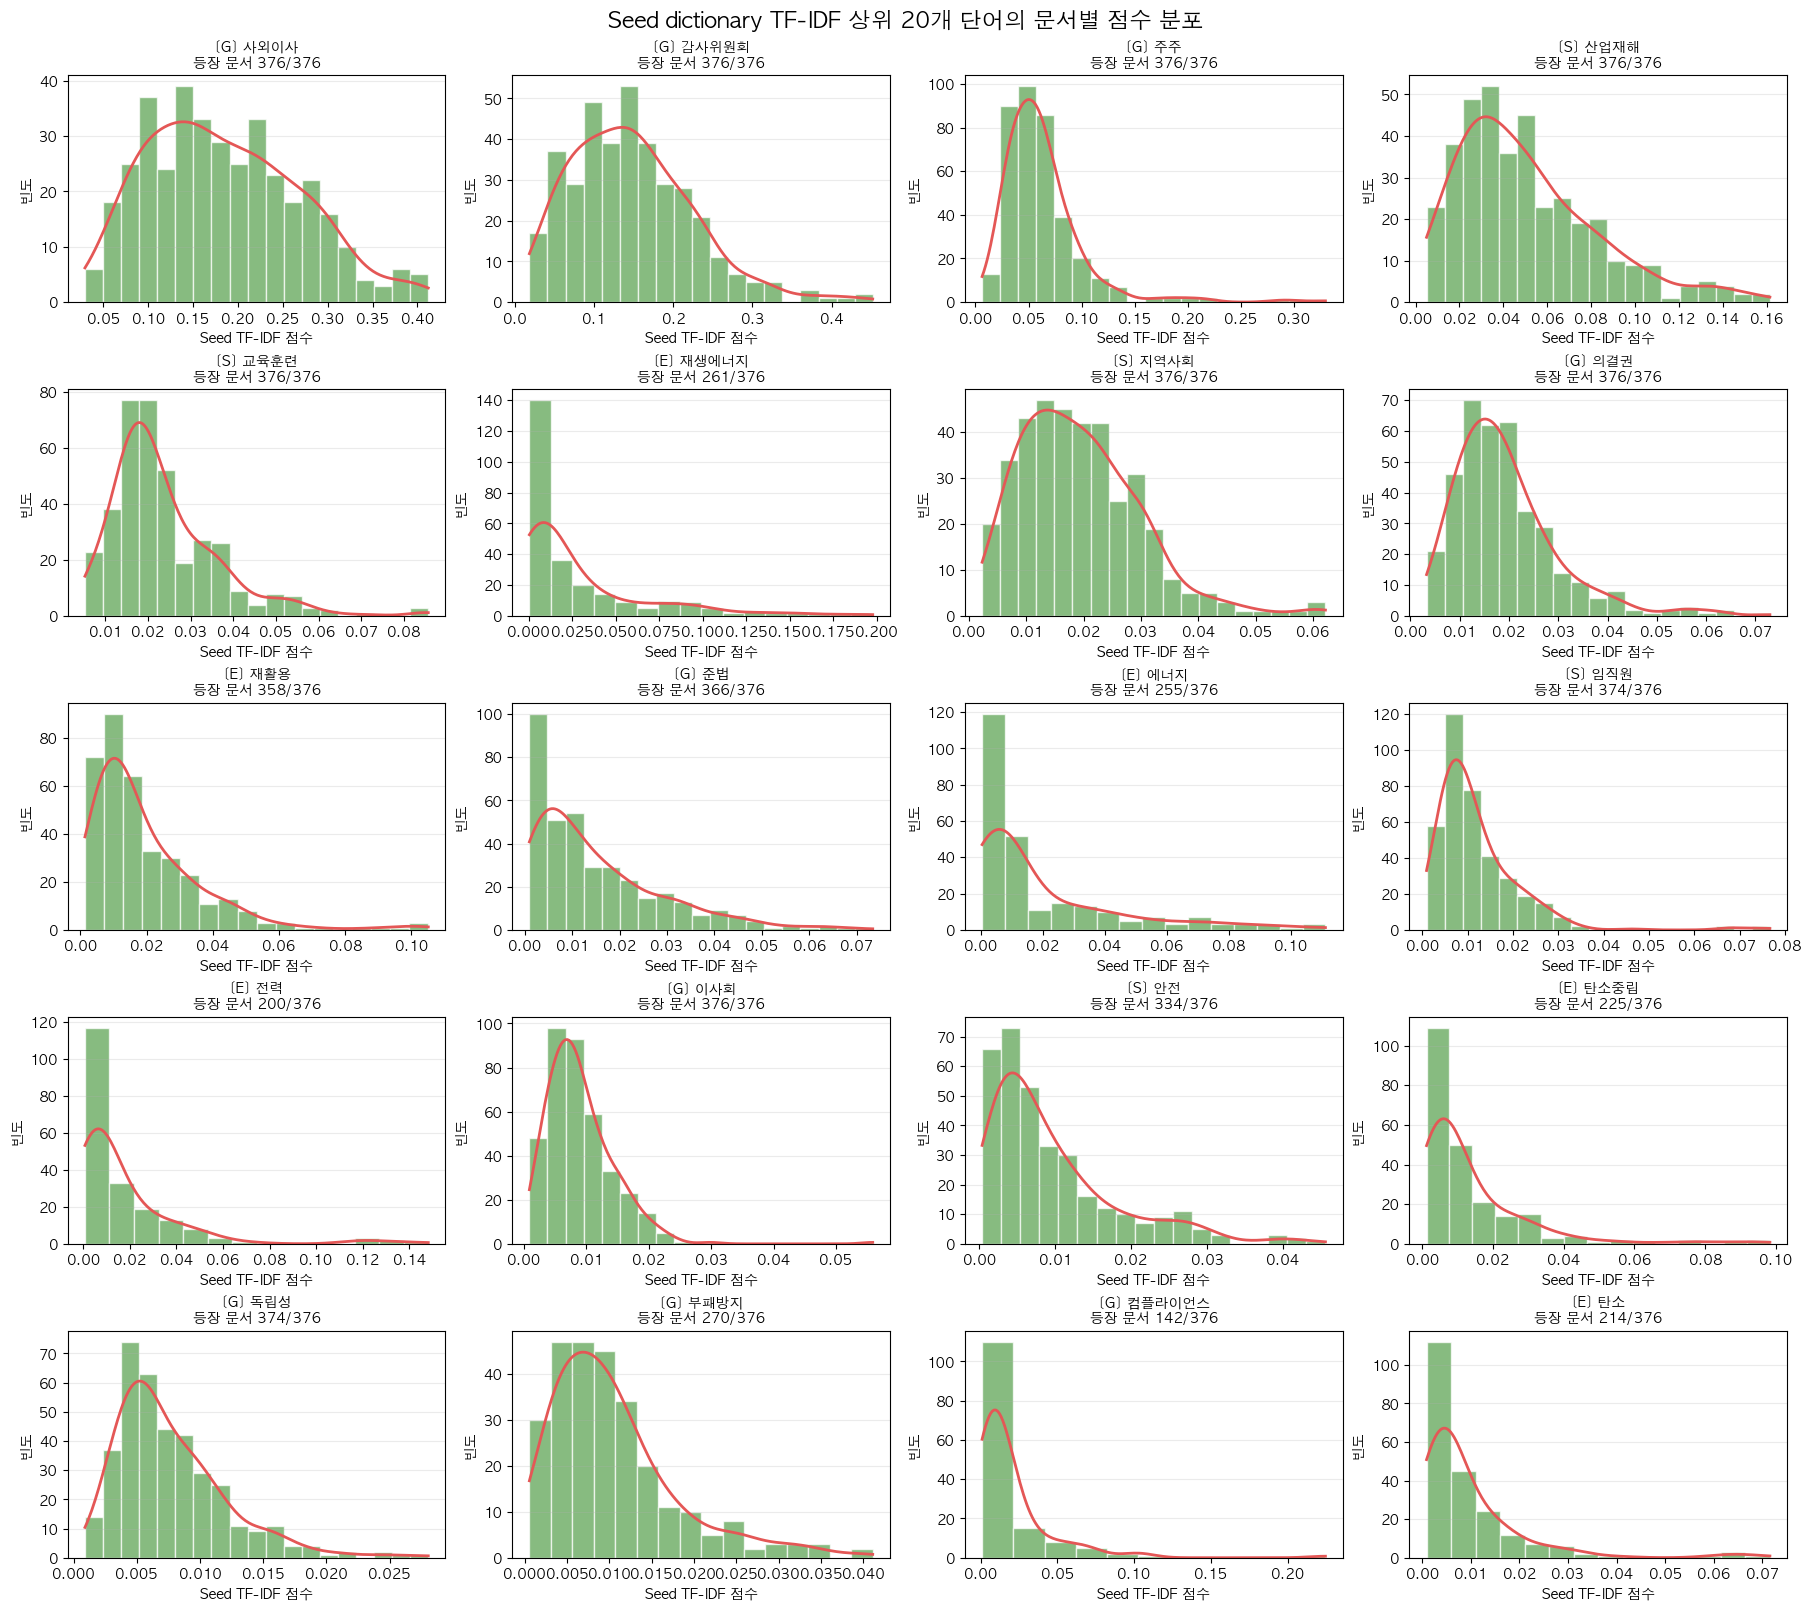

,dimension,seed_term,doc_count,mean,median,std,min,max
0,G,사외이사,376,0.184201,0.176812,0.083861,0.029516,0.412066
1,G,감사위원회,376,0.146821,0.139388,0.077381,0.017872,0.452121
2,G,주주,376,0.062446,0.054683,0.038403,0.006268,0.329684
3,S,산업재해,376,0.050388,0.043752,0.031742,0.005008,0.161529
4,S,교육훈련,376,0.023700,0.019948,0.012755,0.005201,0.085754
5,E,재생에너지,261,0.029077,0.011719,0.038760,0.000501,0.197711
6,S,지역사회,376,0.019334,0.017958,0.010498,0.002287,0.062160
7,G,의결권,376,0.019285,0.017394,0.010634,0.003287,0.072926
8,E,재활용,358,0.019371,0.013964,0.017044,0.001353,0.105126
9,G,준법,366,0.015183,0.010731,0.013695,0.000964,0.073411


In [17]:
import math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager, rcParams

# 한글 폰트 설정: 환경에 있는 폰트를 자동 선택합니다.
available_fonts = {font.name for font in font_manager.fontManager.ttflist}
for font_name in ["AppleGothic", "NanumGothic", "Malgun Gothic"]:
    if font_name in available_fonts:
        rcParams["font.family"] = font_name
        break
rcParams["axes.unicode_minus"] = False


def gaussian_like_curve(values: np.ndarray, points: int = 200):
    """히스토그램 위에 얹을 부드러운 분포 곡선을 간단 KDE로 계산합니다."""
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    if len(values) < 2:
        return None, None

    std = values.std(ddof=1)
    if std == 0:
        return None, None

    bandwidth = 1.06 * std * (len(values) ** (-1 / 5))
    if bandwidth <= 0:
        return None, None

    x_min, x_max = values.min(), values.max()
    if x_min == x_max:
        return None, None

    grid = np.linspace(x_min, x_max, points)
    z = (grid[:, None] - values[None, :]) / bandwidth
    density = np.exp(-0.5 * z ** 2).mean(axis=1) / (bandwidth * np.sqrt(2 * np.pi))
    return grid, density

TOP_N = 20
INCLUDE_ZERO_SCORES = False

seed_top_terms = seed_term_rank.head(TOP_N)[["dimension", "seed_term"]].to_records(index=False)
n_docs = seed_term_scores.shape[0]

summary_rows = []
fig, axes = plt.subplots(5, 4, figsize=(18, 16), constrained_layout=True)
axes = axes.ravel()

for ax, (dimension, seed_term) in zip(axes, seed_top_terms):
    score_col = f"seed_{dimension}_{seed_term}"
    scores = seed_term_scores[score_col].to_numpy(dtype=float)
    values = scores if INCLUDE_ZERO_SCORES else scores[scores > 0]

    summary_rows.append({
        "dimension": dimension,
        "seed_term": seed_term,
        "doc_count": int((scores > 0).sum()),
        "mean": float(values.mean()) if len(values) else 0,
        "median": float(np.median(values)) if len(values) else 0,
        "std": float(values.std(ddof=1)) if len(values) > 1 else 0,
        "min": float(values.min()) if len(values) else 0,
        "max": float(values.max()) if len(values) else 0,
    })

    if len(values) == 0:
        ax.set_title(f"[{dimension}] {seed_term}")
        ax.text(0.5, 0.5, "값 없음", ha="center", va="center", transform=ax.transAxes)
        ax.axis("off")
        continue

    bins = min(20, max(5, int(math.sqrt(len(values)))))
    counts, bin_edges, _ = ax.hist(
        values,
        bins=bins,
        color="#59A14F",
        alpha=0.72,
        edgecolor="white",
    )

    grid, density = gaussian_like_curve(values)
    if grid is not None:
        bin_width = bin_edges[1] - bin_edges[0]
        ax.plot(grid, density * len(values) * bin_width, color="#E45756", linewidth=2)

    ax.set_title(f"[{dimension}] {seed_term}\n등장 문서 {int((scores > 0).sum())}/{n_docs}", fontsize=10)
    ax.set_xlabel("Seed TF-IDF 점수")
    ax.set_ylabel("빈도")
    ax.grid(axis="y", alpha=0.25)

for ax in axes[len(seed_top_terms):]:
    ax.axis("off")

fig.suptitle("Seed dictionary TF-IDF 상위 20개 단어의 문서별 점수 분포", fontsize=16)
plt.show()

seed_tfidf_top20_distribution = pd.DataFrame(summary_rows)
display(seed_tfidf_top20_distribution)



